In [7]:
import sys
sys.path.append("..")

from src.data_prep import load_and_clean_data

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_clean = load_and_clean_data(DATA_PATH)
df_clean.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


TypeError: dtype 'str' does not support operation 'mean'

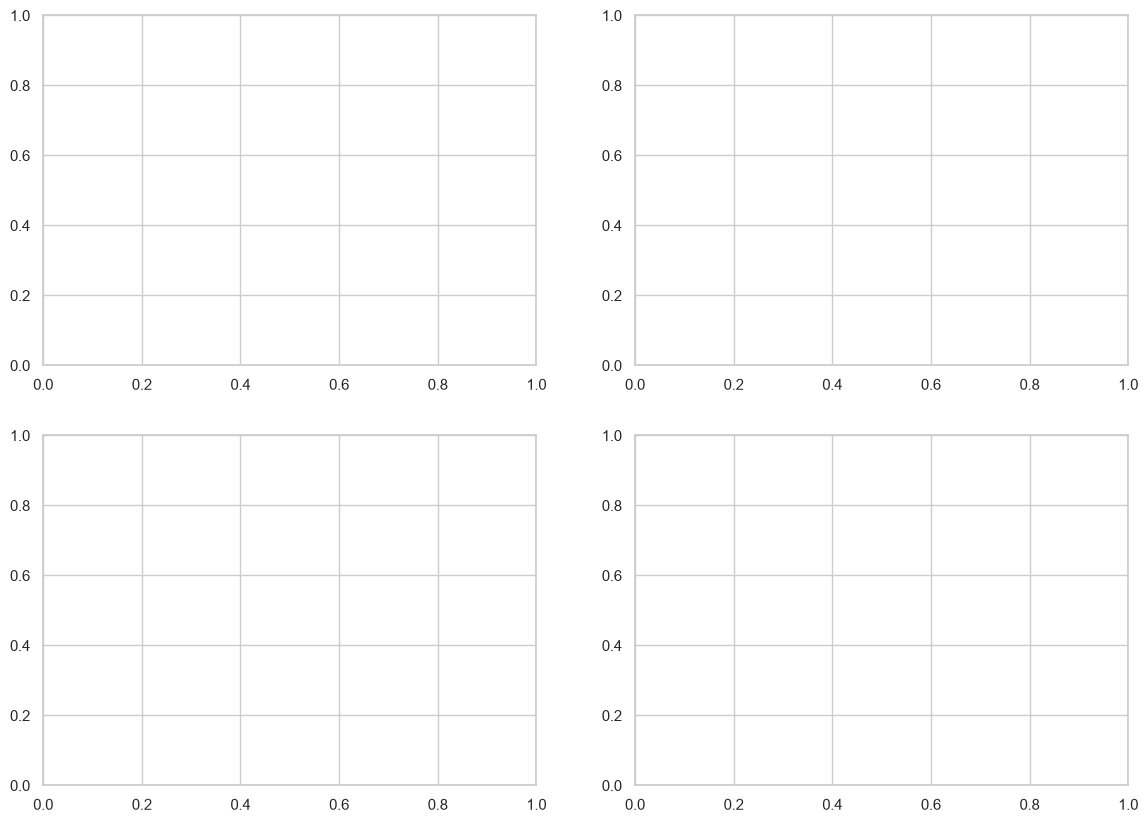

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

cat_features = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, cat_features):
    # Compute churn rate (%) per category, sorted descending
    churn_rate = (
        df_clean.groupby(col)["Churn"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )
    sns.barplot(x=churn_rate.index, y=churn_rate.values, ax=ax, hue=churn_rate.index, legend=False)
    ax.set_title(f"Churn Rate (%) by {col}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=15)

    # Annotate bar values
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

In [ ]:
num_features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, num_features):
    sns.kdeplot(data=df_clean, x=col, hue="Churn", fill=True, common_norm=False, alpha=0.4, ax=ax)
    ax.set_title(f"{col} Distribution by Churn", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

In [ ]:
import sys
sys.path.append("..")

from src.data_prep import load_and_clean_data

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_clean = load_and_clean_data(DATA_PATH)

In [10]:
import sys
import importlib
sys.path.append("..")

import src.data_prep as data_prep
importlib.reload(data_prep)  # Forces Python to read your latest saved file

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from src.train import split_data, build_preprocessor

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_feat = data_prep.add_features(data_prep.load_and_clean_data(DATA_PATH))

X_train, X_test, y_train, y_test = split_data(df_feat)

print(f"Train shape: {X_train.shape} | Churn rate: {y_train.mean():.3f}")
print(f"Test shape:  {X_test.shape}  | Churn rate: {y_test.mean():.3f}")

preprocessor = build_preprocessor(X_train)
sample_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

sample_pipe.fit(X_train, y_train)
print(f"Transformed feature count: {sample_pipe.named_steps['preprocessor'].transform(X_train).shape[1]}")
print(f"Quick sanity-check test accuracy: {sample_pipe.score(X_test, y_test):.4f}")

Train shape: (5634, 23) | Churn rate: 0.265
Test shape:  (1409, 23)  | Churn rate: 0.265
Transformed feature count: 52
Quick sanity-check test accuracy: 0.7991


In [11]:
import importlib
import src.train as train_mod
importlib.reload(train_mod)

cv_results = train_mod.benchmark_models_cv(X_train, y_train)
cv_results.style.format(
    {"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}", "ROC-AUC": "{:.4f}"}
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,CV Time (s)
0,RandomForest (SMOTE),0.7884,0.5865,0.6870,0.6325,0.8419,2.820000
1,RandomForest (Balanced),0.7666,0.5440,0.7485,0.6299,0.8448,1.160000
2,LogReg (Balanced),0.7504,0.5194,0.7987,0.6293,0.8457,0.180000
3,LogReg (SMOTE),0.7536,0.5239,0.7866,0.6288,0.8443,1.450000
4,HistGB (Balanced),0.7655,0.5427,0.7385,0.6256,0.8387,1.980000
5,DecisionTree (Balanced),0.7245,0.4894,0.7953,0.6053,0.8151,0.180000
6,KNN (SMOTE),0.6951,0.4590,0.8368,0.5928,0.8110,0.610000
7,LogReg (Default),0.8055,0.6667,0.5344,0.5926,0.8459,9.900000
8,KNN (Default),0.7868,0.6044,0.5719,0.5875,0.8247,2.860000
9,RandomForest (Default),0.8023,0.6738,0.4983,0.5722,0.8428,1.400000


In [14]:
import importlib
import src.train as train_mod
importlib.reload(train_mod)

tuned_searches = train_mod.tune_top_models(X_train, y_train)

for name, search in tuned_searches.items():
    print(f"=== {name} ===")
    print(f"Best CV F1 Score: {search.best_score_:.4f}")
    print(f"Best Params:      {search.best_params_}\n")

=== LogReg (Tuned) ===
Best CV F1 Score: 0.6338
Best Params:      {'model__C': 0.01, 'model__class_weight': {0: 1, 1: 2.5}}

=== HistGB (Tuned) ===
Best CV F1 Score: 0.6393
Best Params:      {'model__min_samples_leaf': 20, 'model__max_iter': 200, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__l2_regularization': 1.0, 'model__class_weight': {0: 1, 1: 2}}



,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (ms),Predict Time (ms)
0,HistGB (Tuned),0.7764,0.5603,0.7326,0.6350,0.8437,745.200000,31.500000
1,RandomForest (Balanced),0.7644,0.5396,0.7647,0.6327,0.8401,542.800000,122.500000
2,LogReg (Tuned),0.7544,0.5257,0.7647,0.6231,0.8410,61.100000,21.900000
3,DecisionTree (Balanced),0.7268,0.4908,0.7888,0.6051,0.8203,71.800000,23.100000
4,KNN (Default),0.7800,0.5860,0.5829,0.5845,0.8198,37.900000,143.000000



Best Model on Test Set (by F1): HistGB (Tuned)


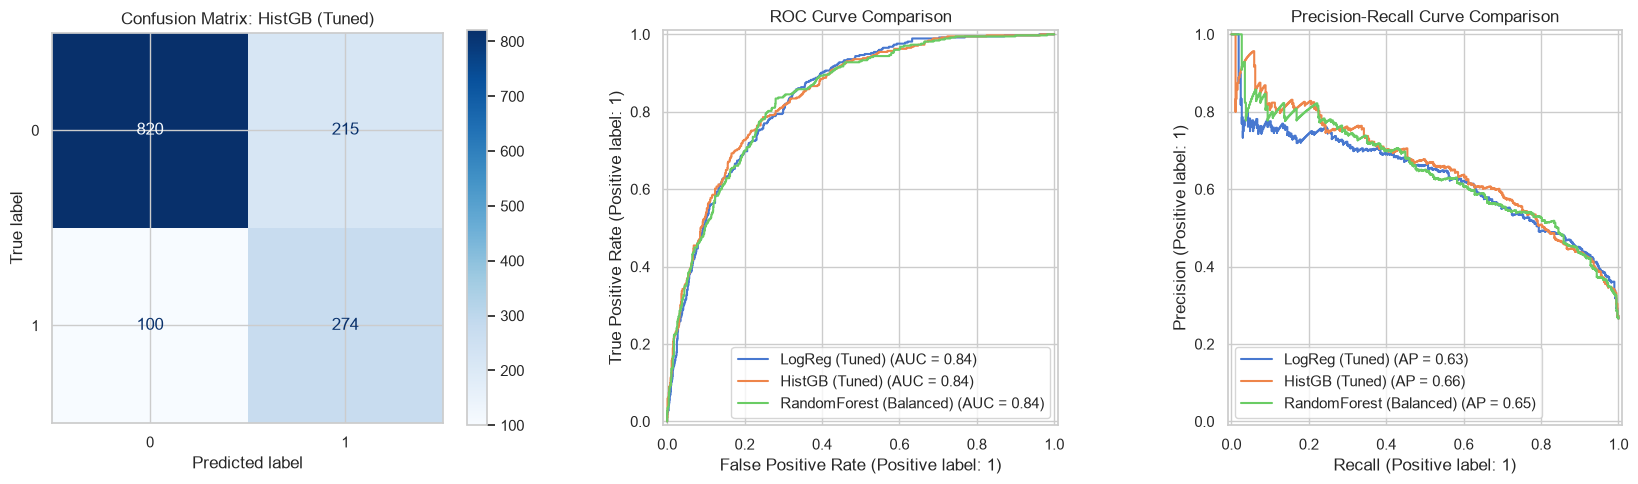

In [15]:
import importlib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import src.train as train_mod

importlib.reload(train_mod)

# Build the final comparison suite (Tuned top 2 + balanced/baseline peers)
models_to_evaluate = {
    "LogReg (Tuned)": tuned_searches["LogReg (Tuned)"].best_estimator_,
    "HistGB (Tuned)": tuned_searches["HistGB (Tuned)"].best_estimator_,
    "RandomForest (Balanced)": Pipeline([
        ("preprocessor", train_mod.build_preprocessor(X_train)),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1)),
    ]),
    "DecisionTree (Balanced)": Pipeline([
        ("preprocessor", train_mod.build_preprocessor(X_train)),
        ("model", DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42)),
    ]),
    "KNN (Default)": Pipeline([
        ("preprocessor", train_mod.build_preprocessor(X_train)),
        ("model", KNeighborsClassifier(n_neighbors=15)),
    ]),
}

test_results, fitted_models = train_mod.evaluate_models_on_test(
    models_to_evaluate, X_train, y_train, X_test, y_test
)
display(test_results.style.format(
    {"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}", "ROC-AUC": "{:.4f}"}
))

# Select the best model by F1 score
best_model_name = test_results.iloc[0]["Model"]
best_pipe = fitted_models[best_model_name]
print(f"\nBest Model on Test Set (by F1): {best_model_name}")

# Plot Confusion Matrix, ROC Curve, and Precision-Recall Curve
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ConfusionMatrixDisplay.from_estimator(best_pipe, X_test, y_test, ax=axes[0], cmap="Blues")
axes[0].set_title(f"Confusion Matrix: {best_model_name}")

for name in ["LogReg (Tuned)", "HistGB (Tuned)", "RandomForest (Balanced)"]:
    RocCurveDisplay.from_estimator(fitted_models[name], X_test, y_test, ax=axes[1], name=name)
axes[1].set_title("ROC Curve Comparison")

for name in ["LogReg (Tuned)", "HistGB (Tuned)", "RandomForest (Balanced)"]:
    PrecisionRecallDisplay.from_estimator(fitted_models[name], X_test, y_test, ax=axes[2], name=name)
axes[2].set_title("Precision-Recall Curve Comparison")

plt.tight_layout()
plt.show()

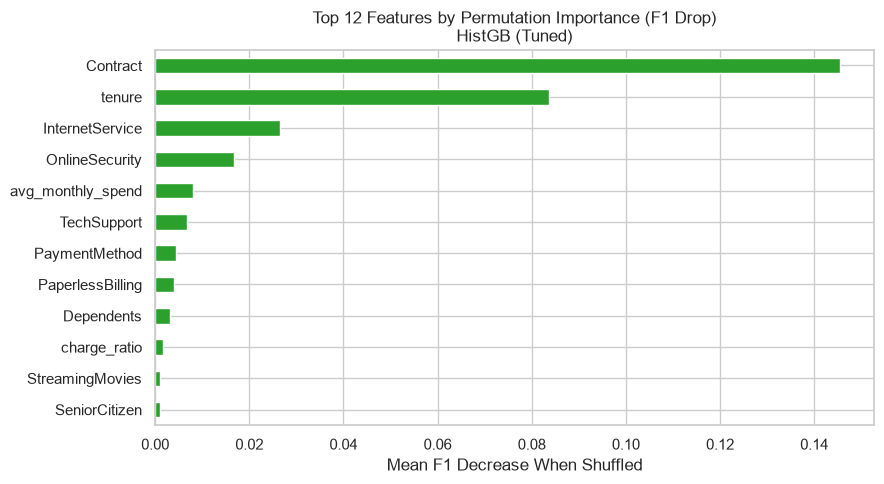

In [16]:
import pandas as pd
import numpy as np
from sklearn.inspection import permutation_importance

feature_names = best_pipe.named_steps["preprocessor"].get_feature_names_out()
model_step = best_pipe.named_steps["model"]

if hasattr(model_step, "coef_"):
    # Exact signed coefficients for Logistic Regression
    coefs = pd.Series(model_step.coef_[0], index=feature_names)
    top_features = pd.concat([coefs.nlargest(8), coefs.nsmallest(8)]).sort_values()

    plt.figure(figsize=(9, 6))
    colors = ["#d62728" if v > 0 else "#1f77b4" for v in top_features.values]
    top_features.plot(kind="barh", color=colors)
    plt.title(f"Top Churn Drivers (Red = Increases Churn, Blue = Reduces Churn)\n{best_model_name}")
    plt.xlabel("Log-Odds Coefficient")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.tight_layout()
    plt.show()
else:
    # Model-agnostic Permutation Importance for HistGB / RandomForest
    perm = permutation_importance(best_pipe, X_test, y_test, scoring="f1", n_repeats=10, random_state=42, n_jobs=-1)
    imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=True).tail(12)

    plt.figure(figsize=(9, 5))
    imp.plot(kind="barh", color="#2ca02c")
    plt.title(f"Top 12 Features by Permutation Importance (F1 Drop)\n{best_model_name}")
    plt.xlabel("Mean F1 Decrease When Shuffled")
    plt.tight_layout()
    plt.show()

In [17]:
interpretability_map = {
    "LogReg (Tuned)": "High (exact signed coefficients / odds ratios)",
    "DecisionTree (Balanced)": "High (visual if/else rules, but high variance)",
    "HistGB (Tuned)": "Medium (needs permutation importance or SHAP)",
    "RandomForest (Balanced)": "Medium (ensemble of 200 trees; needs SHAP)",
    "KNN (Default)": "Low (distance-based black box; no feature weights)",
}

tradeoff_df = test_results.copy()
tradeoff_df["Interpretability"] = tradeoff_df["Model"].map(interpretability_map)

display(
    tradeoff_df[
        ["Model", "F1", "Recall", "ROC-AUC", "Train Time (ms)", "Predict Time (ms)", "Interpretability"]
    ].style.format({"F1": "{:.4f}", "Recall": "{:.4f}", "ROC-AUC": "{:.4f}"})
)

,Model,F1,Recall,ROC-AUC,Train Time (ms),Predict Time (ms),Interpretability
0,HistGB (Tuned),0.6350,0.7326,0.8437,745.200000,31.500000,Medium (needs permutation importance or SHAP)
1,RandomForest (Balanced),0.6327,0.7647,0.8401,542.800000,122.500000,Medium (ensemble of 200 trees; needs SHAP)
2,LogReg (Tuned),0.6231,0.7647,0.8410,61.100000,21.900000,High (exact signed coefficients / odds ratios)
3,DecisionTree (Balanced),0.6051,0.7888,0.8203,71.800000,23.100000,"High (visual if/else rules, but high variance)"
4,KNN (Default),0.5845,0.5829,0.8198,37.900000,143.000000,Low (distance-based black box; no feature weights)
